# 01 - EDA: English, Italian, Roman Urdu
Goal: understand size, label balance, and text length of each dataset.

In [2]:
import sys; sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from src.normalizer import normalize
RAW = Path('../data/raw')

## Load English and Italian

In [3]:
en = pd.read_csv(RAW/'english_train.csv')
it = pd.read_csv(RAW/'italian_train.csv')
print(en.shape, it.shape)
en.head()

(1839, 3) (1839, 3)


,text,source,label
0,okay i\u2019m sorry but TAYLOR SWIFT LOOKS NOT...,sem_eval_2017,2
1,@user the DC comics site has Batman 44 release...,sem_eval_2017,1
2,"""Frank Gaffrey\u002c Cliff May\u002c Steve Eme...",sem_eval_2017,0
3,The tragedy of only thinking up hilarious twee...,sem_eval_2017,2
4,"""Oliseh meets with Victor Moses in London: Sup...",sem_eval_2017,1


## Label balance

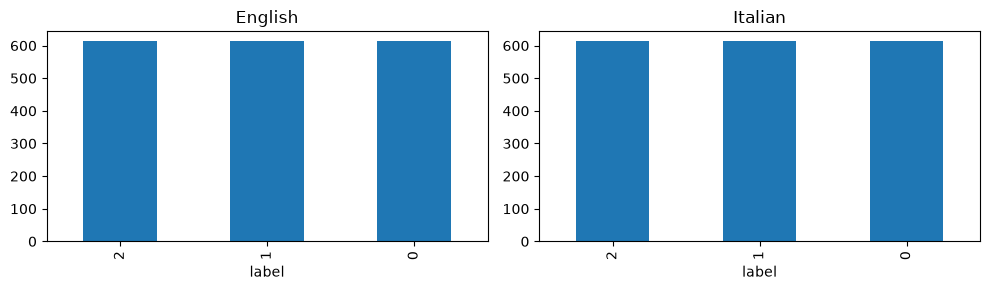

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
en['label'].value_counts().plot.bar(ax=ax[0], title='English')
it['label'].value_counts().plot.bar(ax=ax[1], title='Italian')
plt.tight_layout(); plt.show()

## Text length (words)

In [5]:
for name, df in [('English', en), ('Italian', it)]:
    print(name, df['text'].str.split().str.len().describe().round(1).to_dict())

English {'count': 1839.0, 'mean': 19.6, 'std': 4.9, 'min': 4.0, '25%': 16.0, '50%': 20.0, '75%': 23.0, 'max': 33.0}
Italian {'count': 1839.0, 'mean': 14.8, 'std': 5.8, 'min': 1.0, '25%': 10.0, '50%': 15.0, '75%': 19.0, 'max': 30.0}


## Roman Urdu (after you download it)
Check column names first, then rename to `text` and `label`.

In [7]:
ru = pd.read_csv(RAW/'roman_urdu.csv', header=None)
print(ru.shape)
ru.head()

(20229, 3)


,0,1,2
0,Sai kha ya her kisi kay bus ki bat nhi hai lak...,Positive,NaN
1,sahi bt h,Positive,NaN
2,"Kya bt hai,",Positive,NaN
3,Wah je wah,Positive,NaN
4,Are wha kaya bat hai,Positive,NaN


## Normalizer demo

In [8]:
samples = ['Bohottt achha service!!!', 'delivery bht late thi, packing kharaab']
[normalize(s) for s in samples]

['bohot acha service', 'delivery bohot late thi packing kharab']

## Questions to answer in your notes
1. Are labels balanced in each language?
2. How different are text lengths?
3. How many unique spellings of common Roman Urdu words do you find?

In [9]:
for name, df in [('English', en), ('Italian', it)]:
    print(name)
    print((df['label'].value_counts(normalize=True) * 100).round(1))
    print()

English
label
2    33.3
1    33.3
0    33.3
Name: proportion, dtype: float64

Italian
label
2    33.3
1    33.3
0    33.3
Name: proportion, dtype: float64



In [10]:
ru = ru.rename(columns={0: 'text', 1: 'label'})
print(ru['label'].value_counts())

label
Neutral     8929
Positive    6013
Negative    5286
Neative        1
Name: count, dtype: int64


In [ ]:
vimport re
from collections import Counter
from src.normalizer import VARIANTS

words = Counter(w for t in ru['text'].astype(str) for w in re.findall(r"\w+", t.lower()))

for canon, variants in VARIANTS.items():
    found = {v: words[v] for v in variants if words[v] > 0}
    print(canon, '->', found)